# Etapa 2 — Regressões linear, Ridge e logística

Estimamos **FRP em MW** e classificamos **FRP elevada entre focos já detectados**
no bioma Amazônia brasileiro, sensor AQUA_M-T/INPE. Os seis atributos são
`numero_dias_sem_chuva`, `precipitacao`, `lat`, `lon`, `mes` e `hora_utc`.
A regressão univariada usa apenas **dias sem chuva**. A classe 1 é FRP ≥ Q75 do treino,
a mesma definição da etapa 1; ela não representa uma classificação oficial de dano ambiental.

Todos os ajustes, escolhas e diagnósticos usam 2024. Os cinco folds espaciais são
os mesmos da etapa 1, sem municípios compartilhados entre treino e validação.
Imputação, escala e limiar são aprendidos apenas em cada treino por `utils.py`.
O teste externo de 2025 permanece reservado.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, precision_score, recall_score, f1_score)
from linear import (ajustar_univariada, ajustar_linear, prever_regressao, sigmoide,
                    ajustar_logistica, prever_probabilidade, prever_classe,
                    _objetivo_linear, _objetivo_logistico)
from utils import ATRIBUTOS, carregar_dados, iterar_folds, preparar_particao

np.random.seed(42)
pd.set_option("display.max_rows", 100)
pd.set_option("display.precision", 6)

## Objetivos, atualização e parada

Com $X_b=[1,X]$, a regressão minimiza
$J(\beta)=\|X_b\beta-y\|^2/(2n)+(\lambda/2)\sum_{j=1}^d\beta_j^2$.
Seu gradiente é $X_b^T(X_b\beta-y)/n+\lambda[0,\beta_1,\ldots,\beta_d]$;
o intercepto não é penalizado. Lambda zero recupera a multivariada.

A logística sem regularização usa
$J(\beta)=\mathrm{mean}(\mathrm{logaddexp}(0,z)-yz)$, com $z=X_b\beta$, e
gradiente $X_b^T(\sigma(z)-y)/n$. O módulo implementa as duas expressões e a sigmoide
estável. As referências de biblioteca ficam neste notebook. Na
[documentação do scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html),
`C=np.inf` desativa a penalização logística, mantendo o objetivo comparável.

Em ambos os gradientes, os coeficientes começam em zero; cada passo faz
$\beta\leftarrow\beta-\eta\nabla J$. O histórico registra a perda **após cada atualização**,
de modo que seu tamanho é o número de passos executados. A parada exige norma L2
do gradiente ≤ tolerância, com limite de iterações e aviso caso ele seja atingido.
Aumento de perda ou valores não finitos geram erro explícito.

## Verificações didáticas — dados sintéticos

Os exemplos abaixo verificam os algoritmos do módulo, sem usar linhas do dataset
oficial. As diferenças finitas conferem a função objetivo e o gradiente efetivamente
usados, incluindo o intercepto, para lambda zero e positivo. A tolerância da
comparação numérica é explícita em cada assertiva.

In [2]:
assert np.allclose(ajustar_univariada([0, 1, 2], [1, 3, 5]), [1, 2], atol=1e-12)
assert np.allclose(ajustar_univariada([4, 4, 4], [1, 3, 5]), [3, 0], atol=1e-12)

def conferir_gradiente(objetivo, beta, eps=1e-5):
    _, analitico = objetivo(beta)
    numerico = np.zeros_like(beta)
    for j in range(len(beta)):
        passo = np.zeros_like(beta)
        passo[j] = eps
        numerico[j] = (objetivo(beta + passo)[0] - objetivo(beta - passo)[0]) / (2 * eps)
    assert np.allclose(analitico, numerico, atol=1e-8, rtol=1e-6)

X_sint = np.array([[-1., -1.], [-1., 1.], [1., -1.], [1., 1.]])
Xb_sint = np.column_stack([np.ones(4), X_sint])
y_sint = 3 + X_sint @ np.array([2., -1.])
beta_teste = np.array([-0.3, 0.4, -0.8])
for l2 in [0., 0.7]:
    conferir_gradiente(lambda b: _objetivo_linear(Xb_sint, y_sint, b, l2), beta_teste)

config_sint = dict(taxa_aprendizado=0.1, max_iter=10000, tolerancia=1e-10)
beta_linear, h_linear = ajustar_linear(X_sint, y_sint, **config_sint)
beta_zero, h_zero = ajustar_linear(X_sint, y_sint, lambda_l2=0, **config_sint)
beta_ridge, h_ridge = ajustar_linear(X_sint, y_sint, 0.05, 10000, 1e-10, lambda_l2=10)
assert np.allclose(beta_linear, [3, 2, -1], atol=1e-8)
assert np.array_equal(beta_linear, beta_zero) and np.array_equal(h_linear, h_zero)
assert np.linalg.norm(beta_ridge[1:]) < np.linalg.norm(beta_linear[1:])
assert np.isclose(beta_ridge[0], 3, atol=1e-8)
assert np.allclose(beta_ridge[1:], np.array([2, -1]) / 11, atol=1e-8)
assert np.allclose(prever_regressao(X_sint, beta_linear), y_sint, atol=1e-8)

with np.errstate(over="raise", invalid="raise", divide="raise"):
    assert np.isclose(sigmoide(0), 0.5)
    assert np.array_equal(sigmoide([-1000, 0, 1000]), [0, 0.5, 1])
    perda_extrema, grad_extremo = _objetivo_logistico(
        np.array([[1., -1000.], [1., 1000.]]), np.array([1, 0]), np.array([0., 1.]))
    assert np.isfinite(perda_extrema) and np.isfinite(grad_extremo).all()
conferir_gradiente(lambda b: _objetivo_logistico(Xb_sint, np.array([0, 1, 1, 0]), b), beta_teste)

X_log = np.array([[-1.], [-1.], [-1.], [1.], [1.], [1.]])
y_log = np.array([0, 0, 1, 0, 1, 1])
beta_log, h_log = ajustar_logistica(X_log, y_log, 0.5, 10000, 1e-9)
assert np.allclose(beta_log, [0, np.log(2)], atol=1e-7)
assert np.isfinite(h_log).all() and h_log[-1] < np.log(2)
assert np.array_equal(prever_classe([[0]], [0, 0]), [1])
for historico in [h_linear, h_ridge, h_log]:
    assert len(historico) < 10000 and np.all(np.diff(historico) <= 1e-10)

try:
    ajustar_linear(X_sint, y_sint, 10000, 10, 1e-8)
except FloatingPointError:
    pass
else:
    raise AssertionError("Taxa divergente não foi detectada.")
for chamada in [lambda: ajustar_linear([[0]], [np.nan], 0.1, 10, 1e-8),
                lambda: ajustar_logistica([[0]], [2], 0.1, 10, 1e-8),
                lambda: ajustar_linear([[0]], [1], 0.1, 10, 1e-8, lambda_l2=-1)]:
    try:
        chamada()
    except ValueError:
        pass
    else:
        raise AssertionError("Entrada inválida aceita.")
print("Verificações sintéticas aprovadas: fórmula, gradientes, convergência, L2, sigmoide e logística.")

Verificações sintéticas aprovadas: fórmula, gradientes, convergência, L2, sigmoide e logística.


## Desenvolvimento e configurações

As taxas são configurações de execução para as matrizes preparadas; não são
escolhidas por desempenho no teste. A taxa linear é reduzida para lambdas maiores,
pois a curvatura do objetivo cresce com a penalização. A grade Ridge inclui zero
separadamente e valores positivos espaçados em escala logarítmica. A seleção por
RMSE usa apenas as validações espaciais de 2024.

In [3]:
dados = carregar_dados(2024)
assert len(dados) == 140346 and dados.ano.eq(2024).all()
LAMBDAS = np.r_[0.0, np.logspace(-3, 1, 5)]
TAXA_LINEAR, TAXA_LOGISTICA = 0.1, 0.5
MAX_ITER, TOL_LINEAR, TOL_LOGISTICA = 10000, 1e-7, 1e-7
METRICAS_REG = ["r2", "mae_mw", "rmse_mw"]
METRICAS_CLS = ["acuracia", "precisao", "recall", "f1"]
display(dados.frp.describe(percentiles=[0.5, 0.75, 0.95, 0.99]).rename("FRP_MW").to_frame())
print("Lambdas fixados:", LAMBDAS)

,FRP_MW
count,140346.000000
mean,64.176109
std,152.615864
min,0.000000
50%,27.300000
75%,58.400000
95%,221.700000
99%,619.000000
max,8094.300000


Lambdas fixados: [0.e+00 1.e-03 1.e-02 1.e-01 1.e+00 1.e+01]


## Regressão univariada: dias sem chuva

A representação numérica imputa pela mediana do treino e preserva as unidades.
A fórmula fechada própria e `LinearRegression` usam a mesma coluna e os mesmos
exemplos. A referência constante prevê a **média da FRP do treino**, sem consultar
os alvos da validação. O coeficiente mede MW por dia sem chuva nesta relação linear,
sem interpretação causal.

In [4]:
def metricas_regressao(y, previsto):
    return {"r2": r2_score(y, previsto), "mae_mw": mean_absolute_error(y, previsto),
            "rmse_mw": np.sqrt(mean_squared_error(y, previsto))}

def avaliar_regressao(estrategia, univariada=False, lambdas=(0.0,)):
    resultados, auditoria, exemplos = [], [], {}
    for fold, treino, validacao in iterar_folds(dados, estrategia):
        if estrategia == "espacial":
            assert not set(treino.grupo_validacao) & set(validacao.grupo_validacao)
        else:
            assert treino.data_hora_gmt.max() < validacao.data_hora_gmt.min()
        p = preparar_particao(treino, validacao, "numerica" if univariada else "padronizada")
        colunas = ["numero_dias_sem_chuva"] if univariada else ATRIBUTOS
        X, V = p.X_treino[colunas].to_numpy(), p.X_avaliacao[colunas].to_numpy()
        y, v = p.y_reg_treino.to_numpy(), p.y_reg_avaliacao.to_numpy()
        Xb = np.column_stack([np.ones(len(X)), X])
        modelos = {}
        for l2 in lambdas:
            if univariada:
                beta = ajustar_univariada(X[:, 0], y)
                historico = np.array([])
                nome = "Univariada própria"
            else:
                beta, historico = ajustar_linear(X, y, TAXA_LINEAR / (1 + l2), MAX_ITER,
                                                 TOL_LINEAR, lambda_l2=l2)
                nome = "Multivariada própria" if l2 == 0 else f"Ridge própria λ={l2:g}"
                assert len(historico) < MAX_ITER
                assert np.isfinite(historico).all() and np.all(np.diff(historico) <= 1e-7)
            referencia = LinearRegression() if l2 == 0 else Ridge(alpha=len(X) * l2)
            referencia.fit(X, y)
            beta_ref = np.r_[referencia.intercept_, referencia.coef_]
            perda, gradiente = _objetivo_linear(Xb, y, beta, l2)
            perda_ref, _ = _objetivo_linear(Xb, y, beta_ref, l2)
            diferenca = np.max(np.abs(beta - beta_ref))
            assert diferenca < 1e-3
            assert abs(perda - perda_ref) < 1e-7
            auditoria.append({"fold": fold, "modelo": nome, "lambda": l2,
                              "iteracoes": len(historico), "norma_gradiente": np.linalg.norm(gradiente),
                              "perda_propria": perda, "perda_sklearn": perda_ref,
                              "max_diferenca_coef": diferenca, "intercepto": beta[0],
                              "norma_pesos": np.linalg.norm(beta[1:])})
            modelos[nome] = (prever_regressao(V, beta), l2)
            if l2 == 0:
                modelos["Univariada sklearn" if univariada else "Multivariada sklearn"] = (referencia.predict(V), l2)
            if fold == 0:
                exemplos[float(l2)] = {"beta": beta, "historico": historico,
                                       "X": X, "y": y, "parametros": p.parametros}
        modelos["Média do treino"] = (np.full(len(v), y.mean()), np.nan)
        for nome, (previsto, l2) in modelos.items():
            assert previsto.shape == v.shape and np.isfinite(previsto).all()
            resultados.append({"fold": fold, "modelo": nome, "lambda": l2,
                               "n_treino": len(y), "n_validacao": len(v),
                               **metricas_regressao(v, previsto)})
    return pd.DataFrame(resultados), pd.DataFrame(auditoria), exemplos

reg_univariada, audit_univariada, exemplo_uni = avaliar_regressao("espacial", univariada=True)
display(reg_univariada)
display(reg_univariada.groupby("modelo", sort=False)[METRICAS_REG].agg(["mean", "std"]))
display(audit_univariada[["fold", "intercepto", "max_diferenca_coef"]])
display(pd.Series(exemplo_uni[0.0]["beta"], index=["intercepto_MW", "inclinacao_MW_por_dia"],
                  name="Coeficientes próprios — treino espacial 0").to_frame())

,fold,modelo,lambda,n_treino,n_validacao,r2,mae_mw,rmse_mw
0,0,Univariada própria,0.0,112277,28069,0.007562,56.155897,135.307231
1,0,Univariada sklearn,0.0,112277,28069,0.007562,56.155897,135.307231
2,0,Média do treino,NaN,112277,28069,-0.003556,57.623805,136.063032
3,1,Univariada própria,0.0,112277,28069,0.022008,61.101619,150.984714
4,1,Univariada sklearn,0.0,112277,28069,0.022008,61.101619,150.984714
5,1,Média do treino,NaN,112277,28069,-0.000139,62.102531,152.684703
6,2,Univariada própria,0.0,112276,28070,0.019299,60.685512,134.833700
7,2,Univariada sklearn,0.0,112276,28070,0.019299,60.685512,134.833700
8,2,Média do treino,NaN,112276,28070,-0.000250,60.312958,136.170956
9,3,Univariada própria,0.0,112277,28069,0.005377,64.386764,177.993817


r2               mae_mw               rmse_mw  \
                       mean       std       mean       std        mean   
modelo                                                                   
Univariada própria  0.01119  0.008941  60.288176  3.003300  150.928709   
Univariada sklearn  0.01119  0.008941  60.288176  3.003300  150.928709   
Média do treino    -0.00112  0.001496  61.503819  2.951083  151.839332   

                               
                          std  
modelo                         
Univariada própria  17.725127  
Univariada sklearn  17.725127  
Média do treino     17.511955

,fold,intercepto,max_diferenca_coef
0,0,52.404570,1.705303e-13
1,1,52.465233,1.371347e-12
2,2,52.482243,1.271871e-12
3,3,49.648789,1.186606e-12
4,4,49.627806,6.252776e-13


,Coeficientes próprios — treino espacial 0
intercepto_MW,52.404570
inclinacao_MW_por_dia,0.547992


## Regressão multivariada por descida de gradiente

Usamos a representação padronizada dos seis atributos; a referência recebe X sem
coluna de 1, pois inclui seu próprio intercepto. A auditoria compara coeficientes,
perdas de treino e norma do gradiente, além das métricas da validação. Não cortamos
previsões negativas, pois isso mudaria a comparação entre os modelos lineares.
As médias/desvios das tabelas usam cinco folds com pesos iguais e desvio amostral
(`ddof=1`); isso não é um intervalo de confiança.

,fold,modelo,lambda,n_treino,n_validacao,r2,mae_mw,rmse_mw
0,0,Multivariada própria,0.0,112277,28069,0.020409,54.638843,134.428629
1,0,Multivariada sklearn,0.0,112277,28069,0.020409,54.638843,134.428629
2,0,Média do treino,NaN,112277,28069,-0.003556,57.623805,136.063032
3,1,Multivariada própria,0.0,112277,28069,0.024288,61.291069,150.808650
4,1,Multivariada sklearn,0.0,112277,28069,0.024288,61.291069,150.808650
5,1,Média do treino,NaN,112277,28069,-0.000139,62.102531,152.684703
6,2,Multivariada própria,0.0,112276,28070,0.030919,60.446277,134.032557
7,2,Multivariada sklearn,0.0,112276,28070,0.030919,60.446277,134.032557
8,2,Média do treino,NaN,112276,28070,-0.000250,60.312958,136.170956
9,3,Multivariada própria,0.0,112277,28069,0.019302,64.229458,176.743425


r2               mae_mw               rmse_mw  \
                         mean       std       mean       std        mean   
modelo                                                                     
Multivariada própria  0.02107  0.007485  60.265830  3.488068  150.171216   
Multivariada sklearn  0.02107  0.007485  60.265830  3.488068  150.171216   
Média do treino      -0.00112  0.001496  61.503819  2.951083  151.839332   

                                 
                            std  
modelo                           
Multivariada própria  17.582647  
Multivariada sklearn  17.582647  
Média do treino       17.511955

,fold,modelo,lambda,iteracoes,norma_gradiente,perda_propria,perda_sklearn,max_diferenca_coef,intercepto,norma_pesos
0,0,Multivariada própria,0.0,1229,9.897103e-08,11965.403496,11965.403496,4.904615e-07,65.795948,42.068847
1,1,Multivariada própria,0.0,1206,9.948093e-08,11383.862655,11383.862655,4.799881e-07,63.816549,44.147106
2,2,Multivariada própria,0.0,1228,9.890439e-08,11978.881838,11978.881838,4.861529e-07,64.606877,42.908803
3,3,Multivariada própria,0.0,1182,9.927710e-08,10322.690712,10322.690712,4.736937e-07,62.757086,37.357366
4,4,Multivariada própria,0.0,1219,9.968034e-08,11228.221390,11228.221390,4.885719e-07,63.904089,41.913137


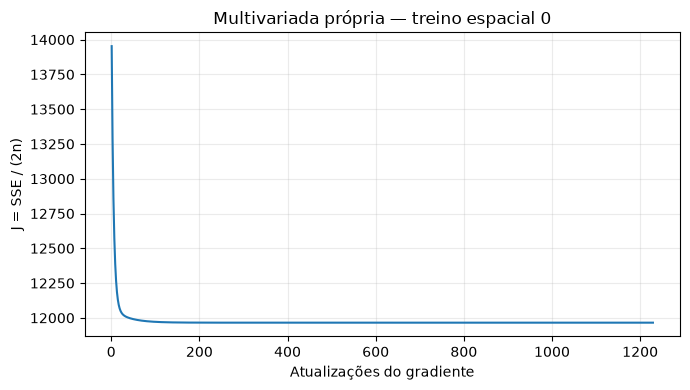

In [5]:
reg_multi, audit_multi, exemplo_multi = avaliar_regressao("espacial")
display(reg_multi)
display(reg_multi.groupby("modelo", sort=False)[METRICAS_REG].agg(["mean", "std"]))
display(audit_multi)
h = exemplo_multi[0.0]["historico"]
plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(h) + 1), h)
plt.xlabel("Atualizações do gradiente")
plt.ylabel("J = SSE / (2n)")
plt.title("Multivariada própria — treino espacial 0")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Ridge: seleção por validação e curva de coeficientes

Mantemos fixos o treino espacial 0 e sua padronização ao visualizar os coeficientes.
Lambda zero é a multivariada anterior; os demais valores são positivos. A escala
`symlog` permite mostrar zero e a parte logarítmica no mesmo eixo.

A comparação adicional com `Ridge` confere o objetivo com **`alpha = n_treino × lambda`**:
a [biblioteca](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)
minimiza SSE + alpha × norma². As perdas de treino são conferidas para cada lambda;
a referência Ridge é uma verificação adicional do projeto. O intercepto permanece
fora da penalização. A configuração de menor RMSE médio é uma **seleção usando a
validação de 2024**, portanto sua métrica não é uma avaliação independente após a escolha.

,fold,modelo,lambda,n_treino,n_validacao,r2,mae_mw,rmse_mw
0,0,Multivariada própria,0.000,112277,28069,0.020409,54.638843,134.428629
1,1,Multivariada própria,0.000,112277,28069,0.024288,61.291069,150.808650
2,2,Multivariada própria,0.000,112276,28070,0.030919,60.446277,134.032557
3,3,Multivariada própria,0.000,112277,28069,0.019302,64.229458,176.743425
4,4,Multivariada própria,0.000,112277,28069,0.010430,60.723503,154.842820
5,0,Ridge própria λ=0.001,0.001,112277,28069,0.020404,54.641574,134.428933
6,0,Ridge própria λ=0.01,0.010,112277,28069,0.020328,54.670105,134.434160
7,0,Ridge própria λ=0.1,0.100,112277,28069,0.018462,55.034366,134.562121
8,0,Ridge própria λ=1,1.000,112277,28069,0.010796,56.178351,135.086625
9,0,Ridge própria λ=10,10.000,112277,28069,0.000256,57.259298,135.804350


,rmse_medio,rmse_desvio,r2_medio,mae_medio
lambda,,,,
0.000,150.171216,17.582647,0.021070,60.265830
0.001,150.170855,17.584589,0.021076,60.256682
0.010,150.170564,17.600487,0.021096,60.184801
0.100,150.273315,17.678567,0.019821,59.945231
1.000,150.851122,17.702871,0.012219,60.355183
10.000,151.593420,17.564715,0.002216,61.214122


Lambda selecionado por RMSE médio espacial em 2024: 0.01


,fold,modelo,lambda,iteracoes,norma_gradiente,perda_propria,perda_sklearn,max_diferenca_coef,intercepto,norma_pesos
0,0,Ridge própria λ=0.001,0.001,1221,9.999350e-08,11966.283097,11966.283097,4.921162e-07,65.795948,41.817278
1,0,Ridge própria λ=0.01,0.010,1160,9.941794e-08,11973.753442,11973.753442,4.607259e-07,65.795948,39.705759
2,0,Ridge própria λ=0.1,0.100,795,9.929688e-08,12022.078416,12022.078416,2.905701e-07,65.795948,27.412125
3,0,Ridge própria λ=1,1.000,396,9.925460e-08,12134.353654,12134.353654,9.925374e-08,65.795948,10.371642
4,0,Ridge própria λ=10,10.000,2224,9.940286e-08,12223.344075,12223.344075,9.940287e-08,65.795948,1.948064
5,1,Ridge própria λ=0.001,0.001,1199,9.953384e-08,11384.831174,11384.831174,4.770135e-07,63.816549,43.876971
6,1,Ridge própria λ=0.01,0.010,1140,9.999903e-08,11393.044704,11393.044704,4.518910e-07,63.816549,41.604150
7,1,Ridge própria λ=0.1,0.100,788,9.927920e-08,11445.254536,11445.254536,2.856241e-07,63.816549,28.162683
8,1,Ridge própria λ=1,1.000,396,9.626873e-08,11552.476359,11552.476359,9.626780e-08,63.816549,9.614380
9,1,Ridge própria λ=10,10.000,2220,9.999946e-08,11625.952857,11625.952857,9.999948e-08,63.816549,1.751207


,intercepto,numero_dias_sem_chuva,precipitacao,lat,lon,mes,hora_utc
lambda,,,,,,,
0.000,65.795948,16.158619,-3.854198,-6.393630,-25.192964,2.084253,-28.529353
0.001,65.795948,16.127573,-3.848383,-6.393576,-25.003665,2.046458,-28.346552
0.010,65.795948,15.860762,-3.798233,-6.390919,-23.411445,1.730224,-26.807158
0.100,65.795948,13.957833,-3.428812,-6.241413,-14.002549,-0.043699,-17.601654
1.000,65.795948,7.722719,-2.019278,-4.175141,-2.062090,-1.271713,-4.533410
10.000,65.795948,1.534214,-0.414299,-0.900381,-0.120933,-0.297337,-0.596470


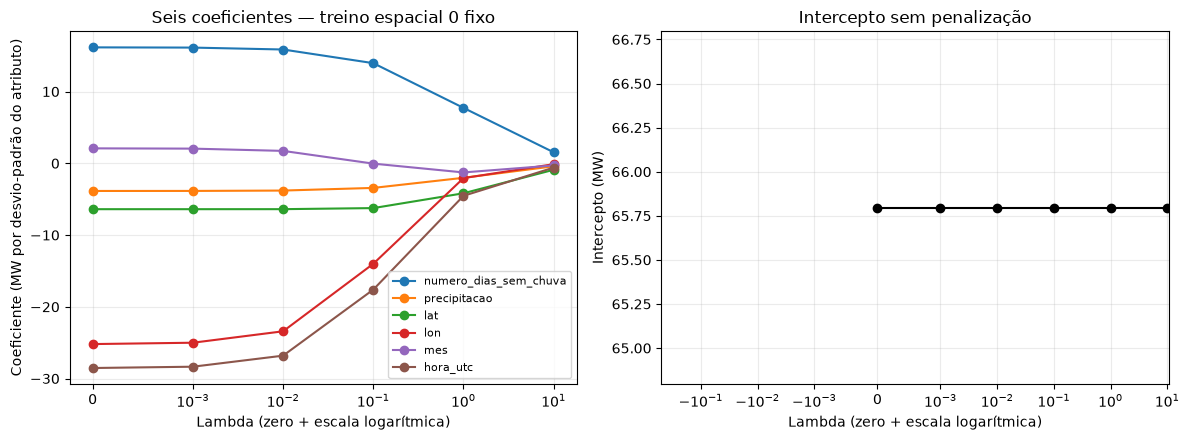

In [6]:
reg_ridge, audit_ridge, exemplo_ridge = avaliar_regressao("espacial", lambdas=LAMBDAS[1:])
reg_grade = pd.concat([reg_multi[reg_multi.modelo.eq("Multivariada própria")],
                       reg_ridge[reg_ridge.modelo.ne("Média do treino")]], ignore_index=True)
selecao_ridge = reg_grade.groupby("lambda").agg(
    rmse_medio=("rmse_mw", "mean"), rmse_desvio=("rmse_mw", "std"),
    r2_medio=("r2", "mean"), mae_medio=("mae_mw", "mean"))
lambda_escolhido = float(selecao_ridge.rmse_medio.idxmin())
display(reg_grade)
display(selecao_ridge)
print(f"Lambda selecionado por RMSE médio espacial em 2024: {lambda_escolhido:g}")
display(audit_ridge)

coeficientes = pd.DataFrame(
    [exemplo_multi[0.0]["beta"]] + [exemplo_ridge[float(l)]["beta"] for l in LAMBDAS[1:]],
    columns=["intercepto"] + ATRIBUTOS, index=pd.Index(LAMBDAS, name="lambda"))
display(coeficientes)
assert np.allclose(coeficientes.intercepto, exemplo_multi[0.0]["beta"][0], atol=1e-5)
assert np.all(np.diff(np.linalg.norm(coeficientes[ATRIBUTOS].to_numpy(), axis=1)) <= 1e-6)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
for atributo in ATRIBUTOS:
    eixos[0].plot(LAMBDAS, coeficientes[atributo], marker="o", label=atributo)
eixos[0].set_ylabel("Coeficiente (MW por desvio-padrão do atributo)")
eixos[0].set_title("Seis coeficientes — treino espacial 0 fixo")
eixos[0].legend(fontsize=8)
eixos[1].plot(LAMBDAS, coeficientes.intercepto, marker="o", color="black")
eixos[1].set_ylabel("Intercepto (MW)")
eixos[1].set_title("Intercepto sem penalização")
eixos[1].set_ylim(coeficientes.intercepto.mean() - 1, coeficientes.intercepto.mean() + 1)
eixos[1].ticklabel_format(axis="y", style="plain", useOffset=False)
for eixo in eixos:
    eixo.set_xscale("symlog", linthresh=0.001)
    eixo.set_xlabel("Lambda (zero + escala logarítmica)")
    eixo.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Logística própria e scikit-learn

As duas versões usam a mesma matriz padronizada e o mesmo Q75 por treino, sem
pesos de classe nem regularização. A referência usa `lbfgs`, que pode seguir uma
trajetória diferente da descida de gradiente. Comparamos perda, probabilidades e
métricas; não exigimos o mesmo número de passos.

O limiar de classificação é **probabilidade ≥ 0,5**, distinto do limiar de FRP em MW.
A referência de maioria usa somente as classes do treino. Precisão, recall e F1
são calculados para a classe 1 com `zero_division=0`.

,fold,modelo,limiar_frp_mw,n_treino,n_validacao,acuracia,precisao,recall,f1
0,0,Logística própria,59.5,112277,28069,0.780826,0.718280,0.052557,0.097947
1,0,Logística sklearn,59.5,112277,28069,0.780826,0.718280,0.052557,0.097947
2,0,Maioria do treino,59.5,112277,28069,0.773594,0.000000,0.000000,0.000000
3,1,Logística própria,58.0,112277,28069,0.748228,0.679727,0.054823,0.101462
4,1,Logística sklearn,58.0,112277,28069,0.748228,0.679727,0.054823,0.101462
5,1,Maioria do treino,58.0,112277,28069,0.740710,0.000000,0.000000,0.000000
6,2,Logística própria,58.6,112276,28070,0.763734,0.711207,0.071470,0.129887
7,2,Logística sklearn,58.6,112276,28070,0.763734,0.711207,0.071470,0.129887
8,2,Maioria do treino,58.6,112276,28070,0.753260,0.000000,0.000000,0.000000
9,3,Logística própria,57.9,112277,28069,0.744772,0.712644,0.042183,0.079651


acuracia            precisao             recall           \
                       mean       std      mean      std      mean      std   
modelo                                                                        
Logística própria  0.756409  0.015766  0.677025  0.06536  0.048038  0.01926   
Logística sklearn  0.756409  0.015766  0.677025  0.06536  0.048038  0.01926   
Maioria do treino  0.749825  0.014465  0.000000  0.00000  0.000000  0.00000   

                         f1            
                       mean       std  
modelo                                 
Logística própria  0.089201  0.034251  
Logística sklearn  0.089201  0.034251  
Maioria do treino  0.000000  0.000000

,fold,iteracoes,norma_gradiente,perda_propria,perda_sklearn,max_diferenca_prob,proporcao_1_treino,proporcao_1_validacao
0,0,911,9.956788e-08,0.543450,0.543450,8.402937e-07,0.250318,0.226406
1,1,897,9.922120e-08,0.543202,0.543202,1.007863e-06,0.250203,0.259290
2,2,911,9.921967e-08,0.543449,0.543449,1.062610e-06,0.250089,0.246740
3,3,883,9.973649e-08,0.542062,0.542062,9.771313e-07,0.250131,0.261819
4,4,909,9.898278e-08,0.539616,0.539616,1.039246e-06,0.250310,0.256618


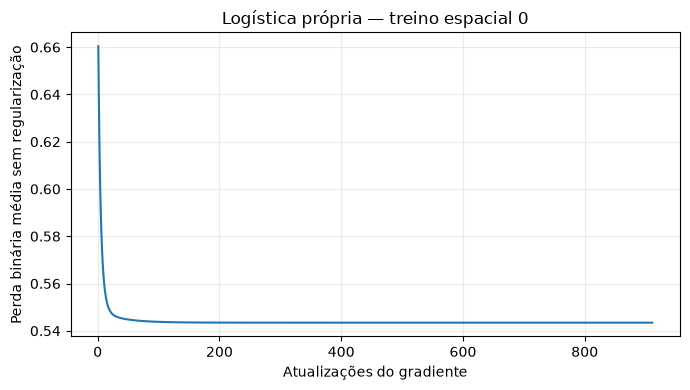

In [7]:
def metricas_classificacao(y, previsto):
    return {"acuracia": accuracy_score(y, previsto),
            "precisao": precision_score(y, previsto, zero_division=0),
            "recall": recall_score(y, previsto, zero_division=0),
            "f1": f1_score(y, previsto, zero_division=0)}

def avaliar_logistica(estrategia):
    resultados, auditoria, exemplo = [], [], None
    for fold, treino, validacao in iterar_folds(dados, estrategia):
        p = preparar_particao(treino, validacao, "padronizada")
        X, V = p.X_treino.to_numpy(), p.X_avaliacao.to_numpy()
        y, v = p.y_cls_treino.to_numpy(), p.y_cls_avaliacao.to_numpy()
        assert list(p.X_treino.columns) == ATRIBUTOS
        assert np.isclose(p.limiar_frp, treino.frp.quantile(0.75))
        beta, h = ajustar_logistica(X, y, TAXA_LOGISTICA, MAX_ITER, TOL_LOGISTICA)
        referencia = LogisticRegression(C=np.inf, solver="lbfgs", fit_intercept=True,
                                        max_iter=10000, tol=1e-9, random_state=42)
        referencia.fit(X, y)
        beta_ref = np.r_[referencia.intercept_, referencia.coef_[0]]
        Xb = np.column_stack([np.ones(len(X)), X])
        perda, gradiente = _objetivo_logistico(Xb, y, beta)
        perda_ref, _ = _objetivo_logistico(Xb, y, beta_ref)
        prob = prever_probabilidade(V, beta)
        prob_ref = referencia.predict_proba(V)[:, 1]
        max_dif_prob = np.max(np.abs(prob - prob_ref))
        assert len(h) < MAX_ITER and np.isfinite(h).all()
        assert np.linalg.norm(gradiente) <= TOL_LOGISTICA * 1.01
        assert np.all(np.diff(h) <= 1e-10)
        assert max_dif_prob < 1e-4 and abs(perda - perda_ref) < 1e-8
        auditoria.append({"fold": fold, "iteracoes": len(h),
                          "norma_gradiente": np.linalg.norm(gradiente),
                          "perda_propria": perda, "perda_sklearn": perda_ref,
                          "max_diferenca_prob": max_dif_prob,
                          "proporcao_1_treino": y.mean(), "proporcao_1_validacao": v.mean()})
        previsoes = {"Logística própria": prever_classe(V, beta),
                     "Logística sklearn": referencia.predict(V),
                     "Maioria do treino": np.full(len(v), np.bincount(y, minlength=2).argmax())}
        for modelo, previsto in previsoes.items():
            assert previsto.shape == v.shape and np.isin(previsto, [0, 1]).all()
            resultados.append({"fold": fold, "modelo": modelo, "limiar_frp_mw": p.limiar_frp,
                               "n_treino": len(y), "n_validacao": len(v),
                               **metricas_classificacao(v, previsto)})
        if fold == 0:
            exemplo = {"beta": beta, "historico": h, "limiar": p.limiar_frp}
    return pd.DataFrame(resultados), pd.DataFrame(auditoria), exemplo

cls_espacial, audit_logistica, exemplo_logistica = avaliar_logistica("espacial")
display(cls_espacial)
display(cls_espacial.groupby("modelo", sort=False)[METRICAS_CLS].agg(["mean", "std"]))
display(audit_logistica)
h = exemplo_logistica["historico"]
plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(h) + 1), h)
plt.xlabel("Atualizações do gradiente")
plt.ylabel("Perda binária média sem regularização")
plt.title("Logística própria — treino espacial 0")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Tabelas consolidadas — avaliação espacial

A regressão reúne a referência de média uma única vez por fold. Os valores de
lambda aparecem explicitamente, com zero na multivariada sem regularização.
Os resultados Ridge pertencem à seleção por validação. R² negativo é preservado
quando observado; nenhuma faixa ilustrativa do gabarito é tratada como meta.

In [8]:
reg_espacial = pd.concat([reg_univariada, reg_multi[reg_multi.modelo.ne("Média do treino")],
                          reg_ridge[reg_ridge.modelo.ne("Média do treino")]], ignore_index=True)
assert not reg_espacial.duplicated(["modelo", "fold"]).any()
assert reg_espacial.groupby("modelo").fold.nunique().eq(5).all()
assert cls_espacial.groupby("modelo").fold.nunique().eq(5).all()
resumo_reg_espacial = reg_espacial.groupby("modelo", sort=False)[METRICAS_REG].agg(["mean", "std"])
resumo_cls_espacial = cls_espacial.groupby("modelo", sort=False)[METRICAS_CLS].agg(["mean", "std"])
display(reg_espacial)
display(resumo_reg_espacial)
display(cls_espacial)
display(resumo_cls_espacial)

,fold,modelo,lambda,n_treino,n_validacao,r2,mae_mw,rmse_mw
0,0,Univariada própria,0.000,112277,28069,0.007562,56.155897,135.307231
1,0,Univariada sklearn,0.000,112277,28069,0.007562,56.155897,135.307231
2,0,Média do treino,NaN,112277,28069,-0.003556,57.623805,136.063032
3,1,Univariada própria,0.000,112277,28069,0.022008,61.101619,150.984714
4,1,Univariada sklearn,0.000,112277,28069,0.022008,61.101619,150.984714
5,1,Média do treino,NaN,112277,28069,-0.000139,62.102531,152.684703
6,2,Univariada própria,0.000,112276,28070,0.019299,60.685512,134.833700
7,2,Univariada sklearn,0.000,112276,28070,0.019299,60.685512,134.833700
8,2,Média do treino,NaN,112276,28070,-0.000250,60.312958,136.170956
9,3,Univariada própria,0.000,112277,28069,0.005377,64.386764,177.993817


r2               mae_mw               rmse_mw  \
                           mean       std       mean       std        mean   
modelo                                                                       
Univariada própria     0.011190  0.008941  60.288176  3.003300  150.928709   
Univariada sklearn     0.011190  0.008941  60.288176  3.003300  150.928709   
Média do treino       -0.001120  0.001496  61.503819  2.951083  151.839332   
Multivariada própria   0.021070  0.007485  60.265830  3.488068  150.171216   
Multivariada sklearn   0.021070  0.007485  60.265830  3.488068  150.171216   
Ridge própria λ=0.001  0.021076  0.007502  60.256682  3.482894  150.170855   
Ridge própria λ=0.01   0.021096  0.007646  60.184801  3.439357  150.170564   
Ridge própria λ=0.1    0.019821  0.008320  59.945231  3.178008  150.273315   
Ridge própria λ=1      0.012219  0.006523  60.355183  2.923500  150.851122   
Ridge própria λ=10     0.002216  0.002089  61.214122  2.949692  151.593420   

                                  
                             std  
modelo                            
Univariada própria     17.725127  
Univariada sklearn     17.725127  
Média do treino        17.511955  
Multivariada própria   17.582647  
Multivariada sklearn   17.582647  
Ridge própria λ=0.001  17.584589  
Ridge própria λ=0.01   17.600487  
Ridge própria λ=0.1    17.678567  
Ridge própria λ=1      17.702871  
Ridge própria λ=10     17.564715

,fold,modelo,limiar_frp_mw,n_treino,n_validacao,acuracia,precisao,recall,f1
0,0,Logística própria,59.5,112277,28069,0.780826,0.718280,0.052557,0.097947
1,0,Logística sklearn,59.5,112277,28069,0.780826,0.718280,0.052557,0.097947
2,0,Maioria do treino,59.5,112277,28069,0.773594,0.000000,0.000000,0.000000
3,1,Logística própria,58.0,112277,28069,0.748228,0.679727,0.054823,0.101462
4,1,Logística sklearn,58.0,112277,28069,0.748228,0.679727,0.054823,0.101462
5,1,Maioria do treino,58.0,112277,28069,0.740710,0.000000,0.000000,0.000000
6,2,Logística própria,58.6,112276,28070,0.763734,0.711207,0.071470,0.129887
7,2,Logística sklearn,58.6,112276,28070,0.763734,0.711207,0.071470,0.129887
8,2,Maioria do treino,58.6,112276,28070,0.753260,0.000000,0.000000,0.000000
9,3,Logística própria,57.9,112277,28069,0.744772,0.712644,0.042183,0.079651


acuracia            precisao             recall           \
                       mean       std      mean      std      mean      std   
modelo                                                                        
Logística própria  0.756409  0.015766  0.677025  0.06536  0.048038  0.01926   
Logística sklearn  0.756409  0.015766  0.677025  0.06536  0.048038  0.01926   
Maioria do treino  0.749825  0.014465  0.000000  0.00000  0.000000  0.00000   

                         f1            
                       mean       std  
modelo                                 
Logística própria  0.089201  0.034251  
Logística sklearn  0.089201  0.034251  
Maioria do treino  0.000000  0.000000

## Diagnóstico temporal complementar

Escolha do projeto: repetir as comparações nos cinco treinos crescentes de 2024,
com validação no bimestre seguinte e parâmetros reaprendidos a cada divisão.
Para Ridge, usamos somente o lambda já selecionado pela validação espacial,
sem repetir a seleção usando o protocolo temporal. Este é um diagnóstico de
transferência entre períodos, separado do espacial e do teste externo.

In [9]:
reg_t_uni, audit_t_uni, _ = avaliar_regressao("temporal", univariada=True)
reg_t_multi, audit_t_multi, _ = avaliar_regressao("temporal")
partes_temporais = [reg_t_uni, reg_t_multi[reg_t_multi.modelo.ne("Média do treino")]]
if lambda_escolhido > 0:
    reg_t_ridge, audit_t_ridge, _ = avaliar_regressao("temporal", lambdas=[lambda_escolhido])
    partes_temporais.append(reg_t_ridge[reg_t_ridge.modelo.ne("Média do treino")])
reg_temporal = pd.concat(partes_temporais, ignore_index=True)
cls_temporal, audit_t_logistica, _ = avaliar_logistica("temporal")
resumo_reg_temporal = reg_temporal.groupby("modelo", sort=False)[METRICAS_REG].agg(["mean", "std"])
resumo_cls_temporal = cls_temporal.groupby("modelo", sort=False)[METRICAS_CLS].agg(["mean", "std"])
display(reg_temporal)
display(resumo_reg_temporal)
display(cls_temporal)
display(resumo_cls_temporal)
display(audit_t_logistica)

,fold,modelo,lambda,n_treino,n_validacao,r2,mae_mw,rmse_mw
0,0,Univariada própria,0.00,5206,3771,-0.038385,31.044258,66.300627
1,0,Univariada sklearn,0.00,5206,3771,-0.038385,31.044258,66.300627
2,0,Média do treino,NaN,5206,3771,-0.054437,34.933765,66.811115
3,1,Univariada própria,0.00,8977,4512,-0.012910,52.068956,123.549618
4,1,Univariada sklearn,0.00,8977,4512,-0.012910,52.068956,123.549618
5,1,Média do treino,NaN,8977,4512,-0.006245,39.772907,123.142440
6,2,Univariada própria,0.00,13489,49700,-0.021208,75.765785,195.478818
7,2,Univariada sklearn,0.00,13489,49700,-0.021208,75.765785,195.478818
8,2,Média do treino,NaN,13489,49700,-0.038665,65.332729,197.142545
9,3,Univariada própria,0.00,63189,57632,0.012863,62.282558,131.155926


r2               mae_mw                rmse_mw  \
                          mean       std       mean        std        mean   
modelo                                                                       
Univariada própria   -0.018057  0.019775  53.341131  16.899533  123.268920   
Univariada sklearn   -0.018057  0.019775  53.341131  16.899533  123.268920   
Média do treino      -0.036926  0.030188  51.449864  13.837381  124.346808   
Multivariada própria -0.036788  0.049760  53.918611  17.820274  123.960291   
Multivariada sklearn -0.036788  0.049760  53.918611  17.820274  123.960291   
Ridge própria λ=0.01 -0.036671  0.050406  53.861270  17.714155  123.941075   

                                 
                            std  
modelo                           
Univariada própria    47.618104  
Univariada sklearn    47.618104  
Média do treino       47.892873  
Multivariada própria  46.864930  
Multivariada sklearn  46.864930  
Ridge própria λ=0.01  46.839370

,fold,modelo,limiar_frp_mw,n_treino,n_validacao,acuracia,precisao,recall,f1
0,0,Logística própria,40.9,5206,3771,0.779899,0.391534,0.444444,0.416315
1,0,Logística sklearn,40.9,5206,3771,0.779899,0.391534,0.444444,0.416315
2,0,Maioria do treino,40.9,5206,3771,0.823389,0.000000,0.000000,0.000000
3,1,Logística própria,36.8,8977,4512,0.674424,0.864583,0.053931,0.101529
4,1,Logística sklearn,36.8,8977,4512,0.674424,0.864583,0.053931,0.101529
5,1,Maioria do treino,36.8,8977,4512,0.658910,0.000000,0.000000,0.000000
6,2,Logística própria,40.5,13489,49700,0.572495,0.505880,0.393182,0.442468
7,2,Logística sklearn,40.5,13489,49700,0.572495,0.505880,0.393182,0.442468
8,2,Maioria do treino,40.5,13489,49700,0.568551,0.000000,0.000000,0.000000
9,3,Logística própria,65.7,63189,57632,0.783384,0.746894,0.037572,0.071545


acuracia            precisao              recall            \
                       mean       std      mean       std      mean       std   
modelo                                                                          
Logística própria  0.734486  0.112494  0.501778  0.337513  0.185826  0.214352   
Logística sklearn  0.734486  0.112494  0.501778  0.337513  0.185826  0.214352   
Maioria do treino  0.738189  0.121739  0.000000  0.000000  0.000000  0.000000   

                         f1            
                       mean       std  
modelo                                 
Logística própria  0.206371  0.207109  
Logística sklearn  0.206371  0.207109  
Maioria do treino  0.000000  0.000000

,fold,iteracoes,norma_gradiente,perda_propria,perda_sklearn,max_diferenca_prob,proporcao_1_treino,proporcao_1_validacao
0,0,898,9.891593e-08,0.500444,0.500444,1.211405e-06,0.250288,0.176611
1,1,854,9.862348e-08,0.491902,0.491902,1.199511e-06,0.250529,0.341090
2,2,751,9.897556e-08,0.517669,0.517669,3.626379e-06,0.250130,0.431449
3,3,977,9.966440e-08,0.543961,0.543961,3.635066e-06,0.250328,0.222134
4,4,829,9.984792e-08,0.545202,0.545202,9.092939e-07,0.250362,0.137772


## Discussão dos resultados

A comparação espacial preservou a FRP em MW e todas as observações válidas de 2024.
A distribuição apresentou média **64,18 MW**, mediana **27,30 MW**, percentil 99 de
**619,00 MW** e máximo **8.094,30 MW**, evidenciando cauda longa. A univariada por
dias sem chuva obteve R² médio **0,011190** e RMSE **150,928709 MW**; a multivariada,
R² **0,021070** e RMSE **150,171216 MW**, frente a **151,839332 MW** da média do treino.
O ganho sobre a referência foi pequeno: relações lineares com estes seis atributos
explicaram apenas uma parcela reduzida da variação. A cauda longa é compatível com
RMSE alto e sensibilidade a extremos, mas as métricas, isoladamente, não demonstram
que ela seja a única causa dessa limitação.

A fórmula fechada e os gradientes próprios concordaram numericamente com as
bibliotecas. Nos folds espaciais, a maior diferença de coeficientes entre linear/Ridge
próprias e referências foi **4,921×10⁻⁷**; na logística, a maior diferença de
probabilidade foi **1,063×10⁻⁶**. Os ajustes atingiram a tolerância antes do limite
de iterações, com perdas decrescentes, conferindo a execução e a convergência
numérica. A curva Ridge reduziu a norma dos pesos com a penalização, preservando
o intercepto. Lambda **0,01** teve o menor RMSE médio (**150,170564 MW**), uma melhora
mínima em relação a lambda zero. Trata-se de seleção na própria validação de 2024,
sem evidência de melhoria relevante ou de desempenho independente após a escolha.

A logística própria e a referência tiveram acurácia espacial média **0,756409**,
contra **0,749825** da maioria, porém recall **0,048038** e F1 **0,089201** para FRP
elevada. A precisão média **0,677025** veio acompanhada de poucos positivos
recuperados; o desequilíbrio de classes limita a leitura da acurácia. No diagnóstico
temporal, a multivariada teve R² médio **−0,036788** e a logística acurácia **0,734486**,
abaixo dos **0,738189** da maioria. Esses resultados negativos foram mantidos e
sugerem limitações na transferência entre períodos. Dependência entre detecções,
ausências, horário do sensor e a representação linear restringem a generalização.
Os protocolos permanecem separados e 2025 não foi aberto; nada aqui comprova
previsão antecipada de incêndios ou classificação de dano ambiental.

## Conferência final

No kernel **FIA (Python 3.12)**, usar **Reiniciar kernel e executar todas as células**
e salvar as saídas. Figuras, tabelas, testes e explicações ficam neste notebook.
Não é produzido relatório nem arquivo externo; 2025 não é carregado.

In [10]:
assert dados.ano.eq(2024).all()
for tabela, metricas in [(reg_espacial, METRICAS_REG), (reg_temporal, METRICAS_REG),
                          (cls_espacial, METRICAS_CLS), (cls_temporal, METRICAS_CLS)]:
    assert tabela.groupby("modelo").fold.nunique().eq(5).all()
    assert np.isfinite(tabela[metricas].to_numpy()).all()
print("Etapa 2 concluída: testes sintéticos, gradientes conferidos, comparações espaciais e diagnóstico temporal.")
print(f"Maior diferença de coeficientes linear/Ridge: {max(audit_multi.max_diferenca_coef.max(), audit_ridge.max_diferenca_coef.max()):.3e}")
print(f"Maior diferença de probabilidade logística espacial: {audit_logistica.max_diferenca_prob.max():.3e}")

Etapa 2 concluída: testes sintéticos, gradientes conferidos, comparações espaciais e diagnóstico temporal.
Maior diferença de coeficientes linear/Ridge: 4.921e-07
Maior diferença de probabilidade logística espacial: 1.063e-06
